# PPE Detection — YOLOv8/Ultralytics Training

Train a small object detector on a Roboflow Universe PPE dataset (helmet, vest, person and other PPE classes, depending on the dataset version). This notebook is **not run**; run it in Google Colab with a GPU.

**Dataset choice:** Construction-site PPE detection. It's a practical two-or-more-class object detection use case and the Roboflow export is YOLO-compatible. Before training, select a public dataset/project version in Roboflow Universe, export/download it in YOLO format, and configure the download cell below with your project/version/API key.

Copy the resulting `runs/detect/ppe_training/weights/best.pt` into the GitHub repository's `models/best.pt` folder for Streamlit deployment.


In [1]:
# 1. Install packages
!pip install -q ultralytics roboflow


In [2]:
from roboflow import Roboflow

ROBOFLOW_API_KEY = "UMRs8hJjvhz6X2UX5mu7"

WORKSPACE = "huiyao-hu-sj18e"
PROJECT = "construction-ppe-detection"
VERSION = 1

rf = Roboflow(api_key=ROBOFLOW_API_KEY)

project = rf.workspace(WORKSPACE).project(PROJECT)

dataset = project.version(VERSION).download("yolov8")

DATASET_DIR = dataset.location

print("Dataset location:", DATASET_DIR)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Construction-PPE-Detection-1 in yolov8:: 100%|██████████| 10034/10034 [00:01<00:00, 6123.61it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset location: /content/Construction-PPE-Detection-1


## 3. Download dataset from Roboflow

Create a Roboflow account, find a public construction/PPE detection dataset in Roboflow Universe, and use its **YOLOv8** export option. Fill in the project slug, workspace slug and version number below. Use your Roboflow API key (keep it private; do not commit it to GitHub).

In [3]:
# 4. Inspect dataset YAML
from pathlib import Path
import yaml

yaml_candidates = list(Path(DATASET_DIR).glob("*.yaml")) + list(Path(DATASET_DIR).glob("*.yml"))
assert yaml_candidates, "No dataset YAML found. Confirm export is YOLO format."
DATA_YAML = str(yaml_candidates[0])
with open(DATA_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)
print(data_cfg)
print("Classes:", data_cfg.get("names"))


{'names': ['boots', 'gloves', 'helmet', 'human', 'vest'], 'nc': 5, 'roboflow': {'license': 'CC BY 4.0', 'project': 'construction-ppe-detection', 'url': 'https://universe.roboflow.com/huiyao-hu-sj18e/construction-ppe-detection/dataset/1', 'version': 1, 'workspace': 'huiyao-hu-sj18e'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}
Classes: ['boots', 'gloves', 'helmet', 'human', 'vest']


In [4]:
# 5. Train for at least 20 epochs (GPU recommended)
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # pretrained nano model
results = model.train(
    data=DATA_YAML,
    epochs=20,
    imgsz=640,
    batch=16,       # reduce to 8 or 4 if GPU memory is limited
    project="runs/detect",
    name="ppe_training",
    patience=10,
    plots=True,
    verbose=True
)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Construction-PPE-Detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_training, nbs=64, nms=None, opset=Non

results.png


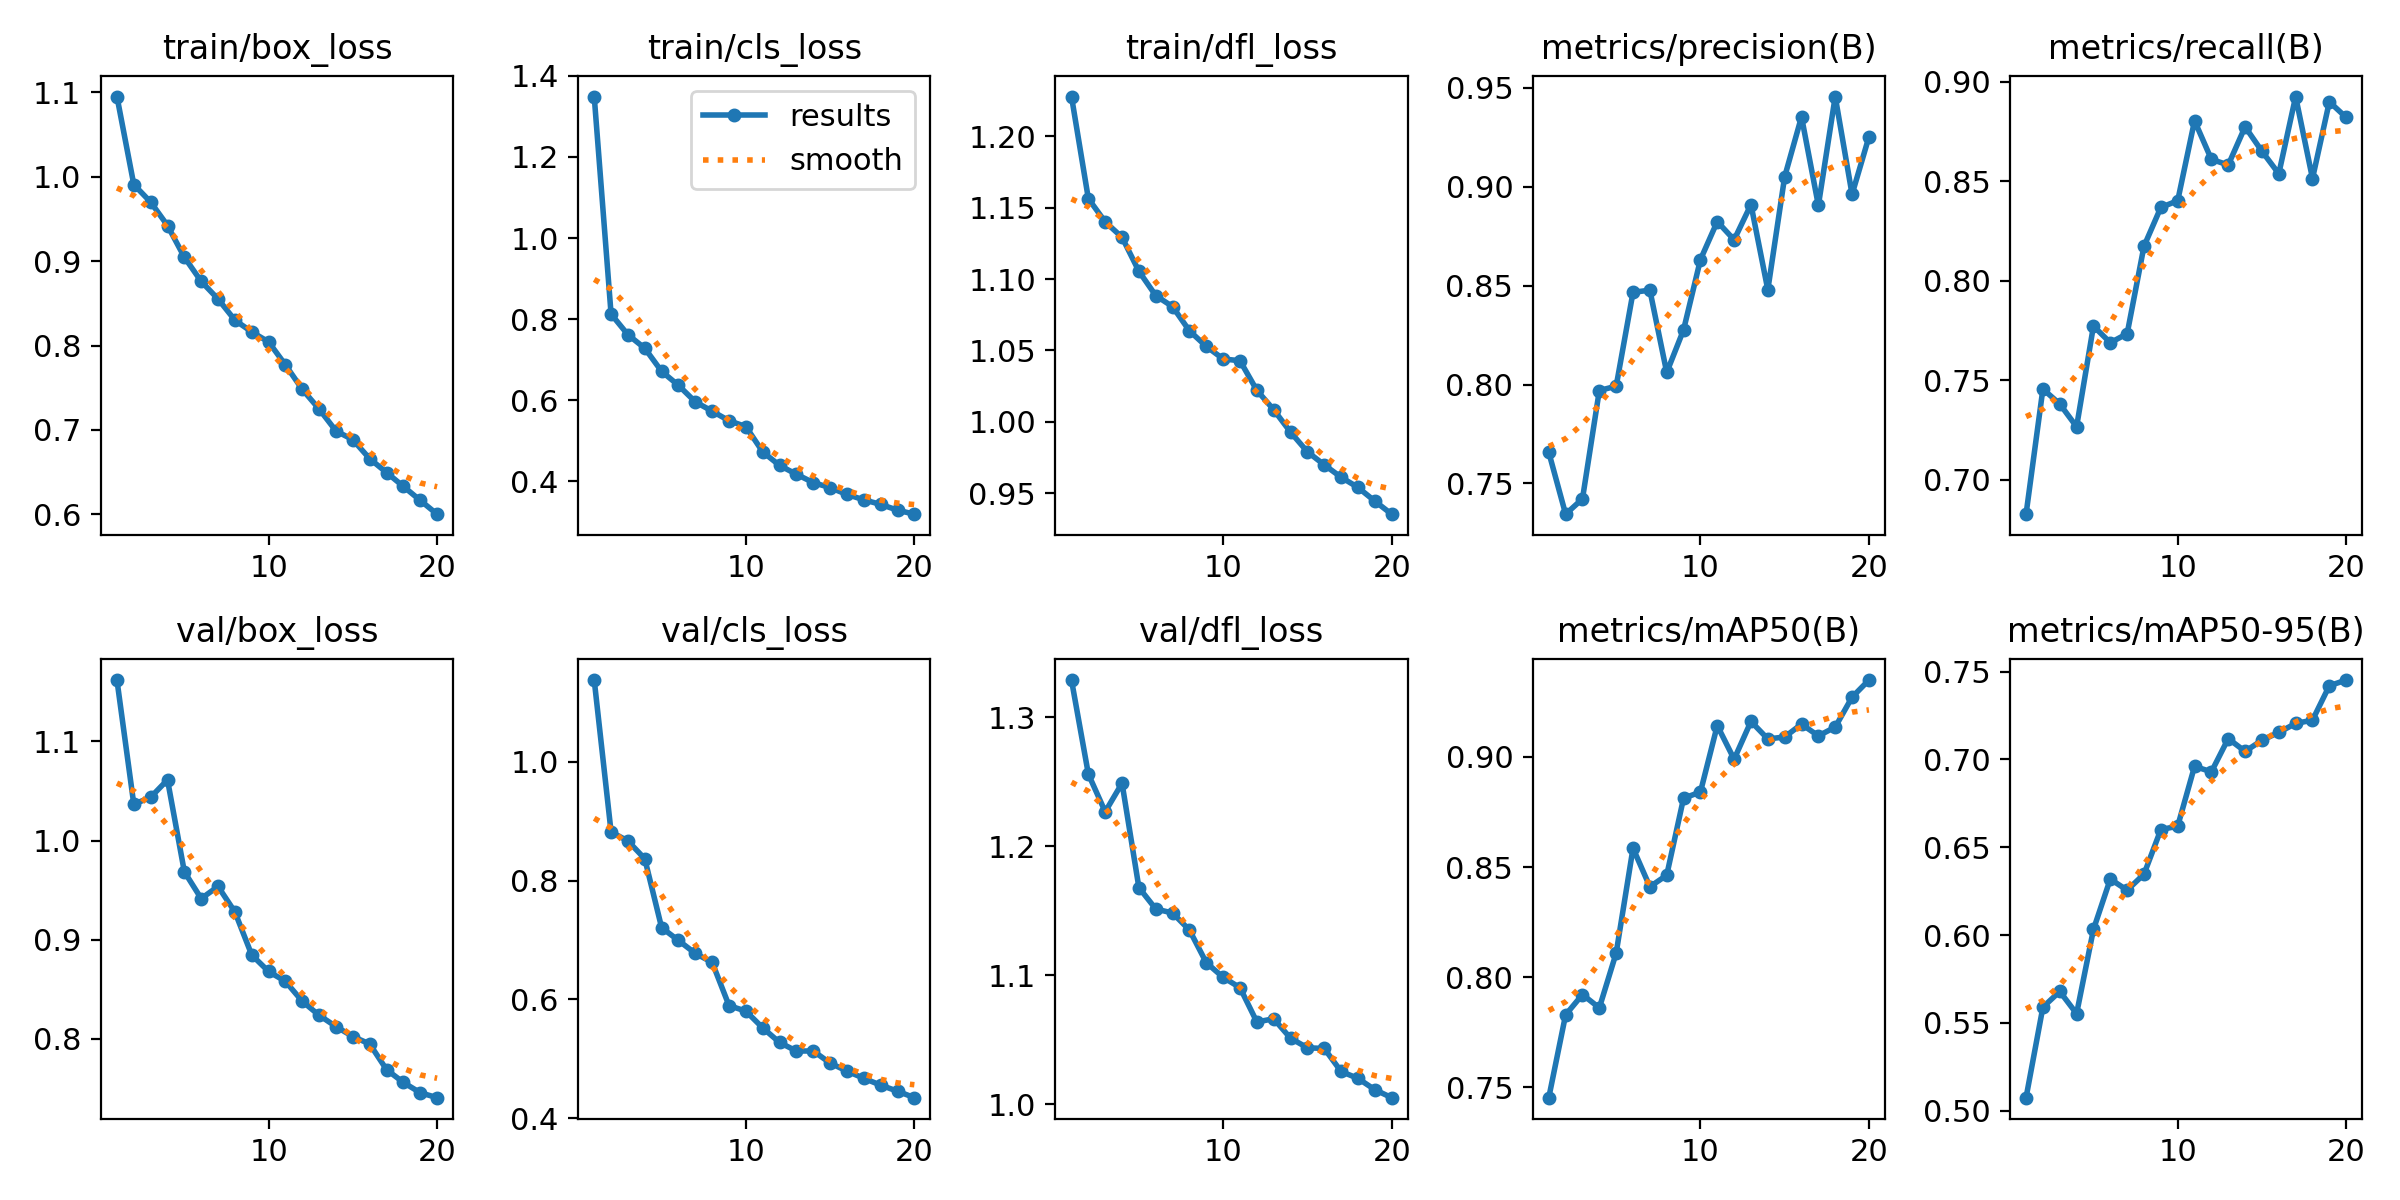

confusion_matrix.png


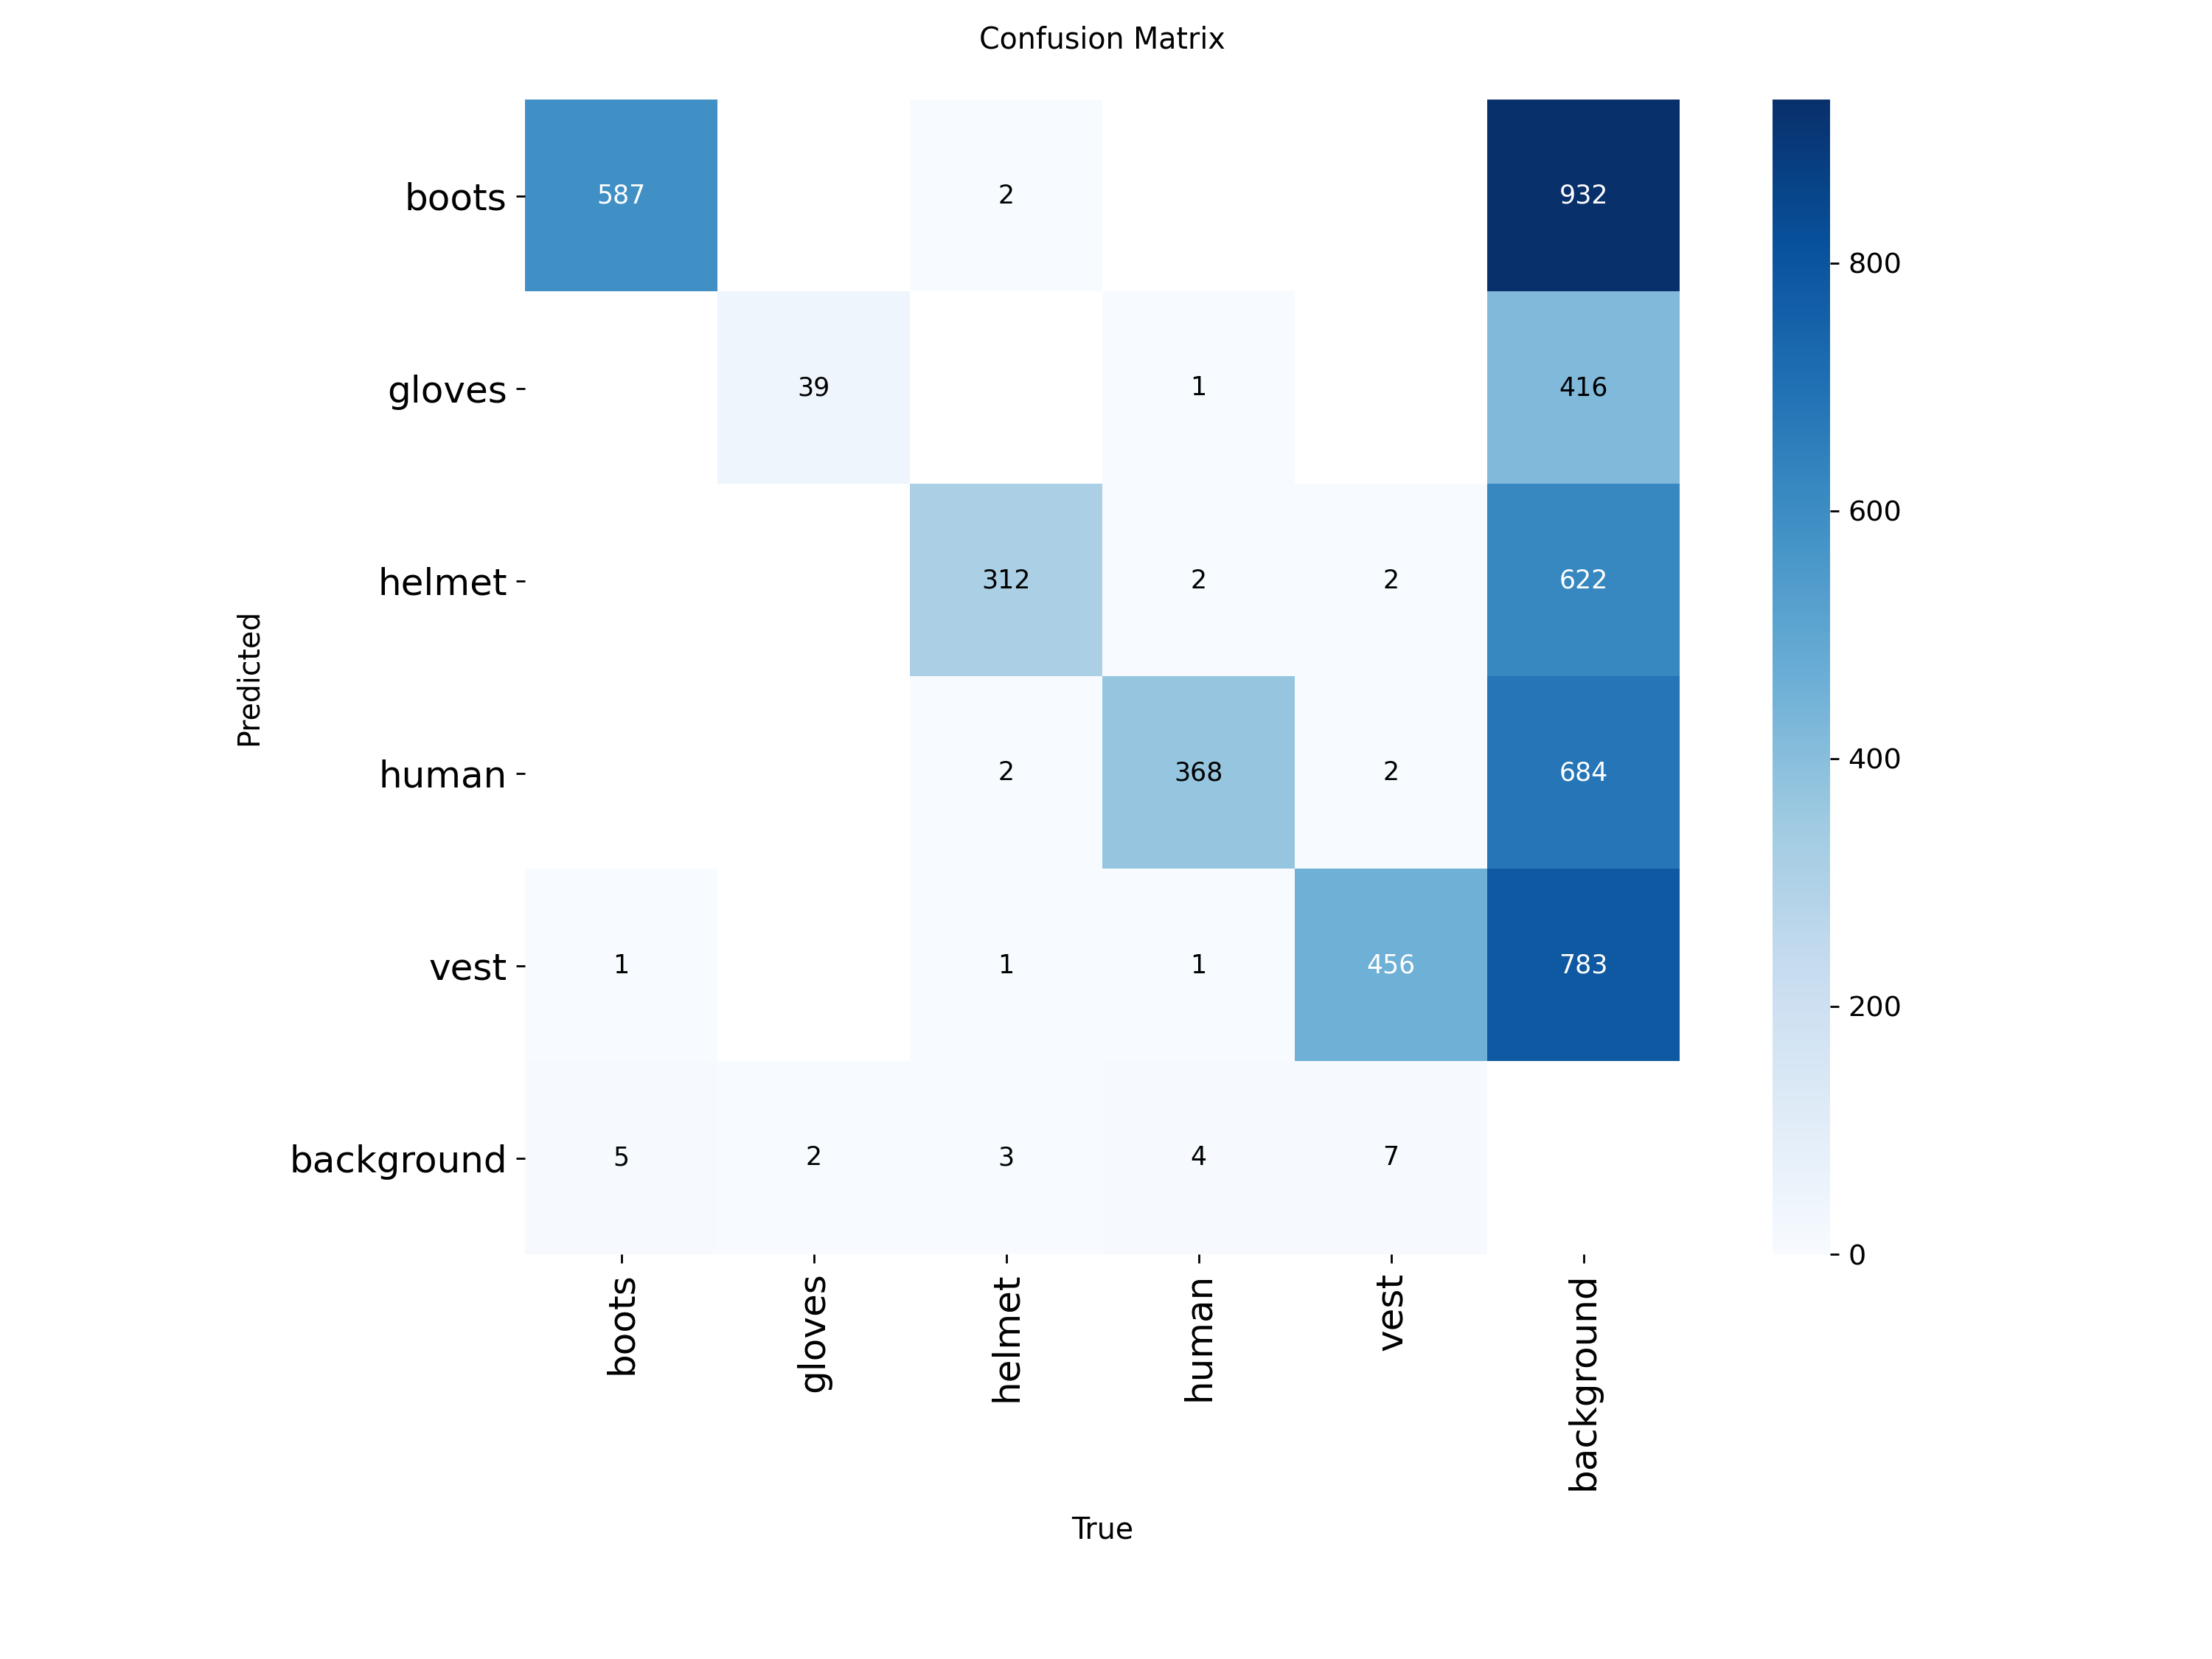

In [8]:
# 6. Inspect training metrics and plots
from IPython.display import display, Image
from pathlib import Path

run_dir = Path("/content/runs/detect/runs/detect/ppe_training")
for plot_name in ["results.png", "confusion_matrix.png", "PR_curve.png", "F1_curve.png"]:
    plot_path = run_dir / plot_name
    if plot_path.exists():
        print(plot_name)
        display(Image(filename=str(plot_path)))

In [7]:
# 7. Evaluate on validation set and print mAP metrics
from pathlib import Path
from ultralytics import YOLO

# Adjusting run_dir to match the actual folder structure where results were saved
run_dir = Path("/content/runs/detect/runs/detect/ppe_training")

trained = YOLO(str(run_dir / "weights" / "best.pt"))
metrics = trained.val(data=DATA_YAML)
print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2099.9±880.1 MB/s, size: 71.2 KB)
val: Scanning /content/Construction-PPE-Detection-1/valid/labels.cache... 420 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 420/420 125.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 4.2it/s 6.4s
                   all        420       1797      0.925      0.882      0.935      0.744
                 boots        276        593      0.971      0.917      0.983      0.744
                gloves         23         41      0.764      0.712      0.787      0.552
                helmet        273        320      0.959      0.941       0.97      0.737
                 human        302        376      0.953       0.91      0.961      0.858
                  vest    

In [9]:
# 8. Save best model and training outputs to Google Drive
import shutil
destination = Path("/content/drive/MyDrive/PPE_YOLO_training")
destination.mkdir(parents=True, exist_ok=True)
shutil.copy2(run_dir / "weights" / "best.pt", destination / "best.pt")
shutil.copy2(run_dir / "weights" / "last.pt", destination / "last.pt")
shutil.copy2(run_dir / "results.csv", destination / "results.csv")
for name in ["results.png", "confusion_matrix.png", "PR_curve.png", "F1_curve.png"]:
    if (run_dir / name).exists():
        shutil.copy2(run_dir / name, destination / name)
print("Saved to:", destination)


Saved to: /content/drive/MyDrive/PPE_YOLO_training


Saving train_batch2741.jpg to train_batch2741 (1).jpg

image 1/1 /content/train_batch2741 (1).jpg: 640x640 5 bootss, 1 helmet, 3 humans, 7 vests, 7.8ms
Speed: 2.6ms preprocess, 7.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


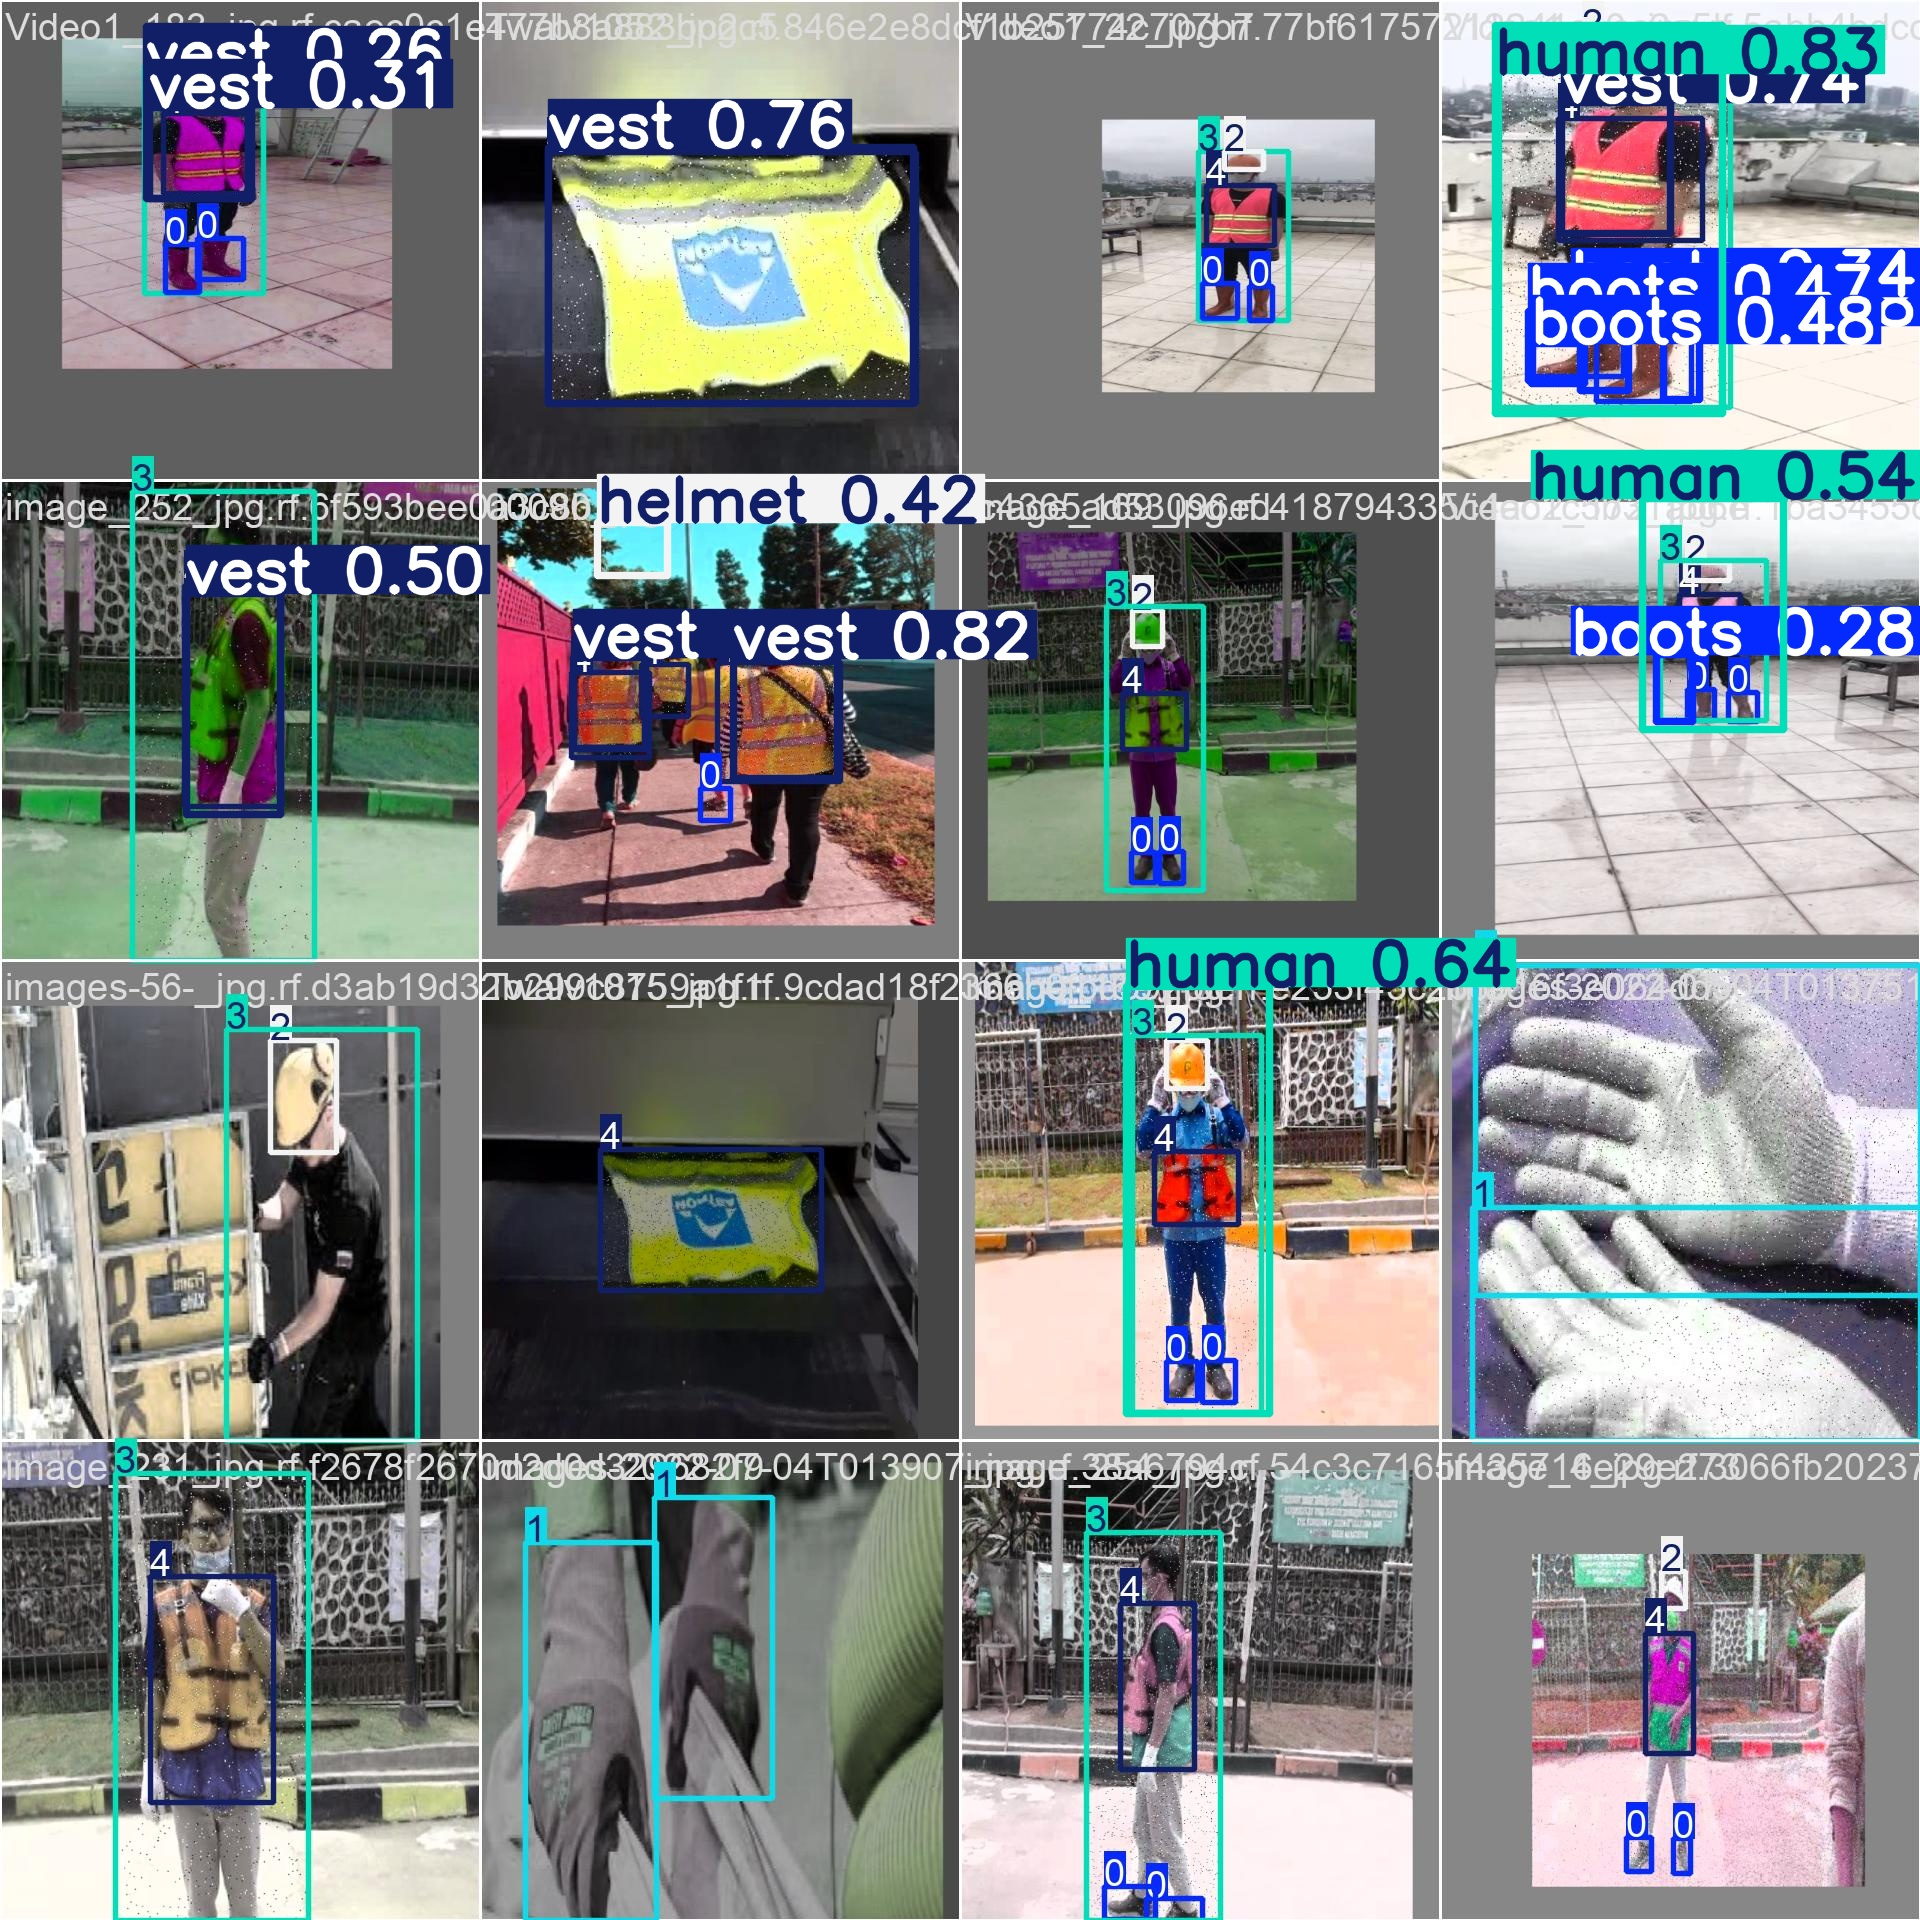

In [11]:
# 9. (Optional) Predict on an image to inspect the detector
# Upload an image or set the path below.
from google.colab import files
from pathlib import Path
from IPython.display import Image, display

uploaded = files.upload()
sample_path = next(iter(uploaded))
pred = trained.predict(source=sample_path, conf=0.25, save=True)

# Wrap pred[0].save_dir with Path() to fix the path combination issue
save_path = Path(pred[0].save_dir) / Path(sample_path).name
display(Image(filename=str(save_path)))